In [98]:
from ultralytics import YOLO
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

print("Current directory:", Path.cwd())
print("Files:", list(Path.cwd().iterdir()))

Current directory: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks
Files: [PosixPath('/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/.ipynb_checkpoints'), PosixPath('/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/01_dataset_exploration.ipynb'), PosixPath('/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/train.ipynb'), PosixPath('/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/yolo_accuaracy.ipynb'), PosixPath('/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/yolo11n.pt')]


In [99]:

# Your notebook is inside Project/notebooks/
PROJECT_ROOT = Path.cwd().parent

DATA_ROOT = PROJECT_ROOT / "data" / "Single Object trajectory"

print("Project:", PROJECT_ROOT)
print("Dataset:", DATA_ROOT)

Project: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project
Dataset: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory


In [199]:
# load data

train_dirs = [
    "/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/Person1", 
    "/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/Person3", 
    "/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/Person4",
    "/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/sofaMan1",
    "/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/sofaMan2",
    "/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/sofaMan4"
    ]

val_dirs = [
    "/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/val/Person2", 
    "/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/sofaMan3", 
    ]


print(f"Found {len(train_dirs)} videos")

for video in train_dirs[:10]:
    print(video)

Found 6 videos
/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/Person1
/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/Person3
/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/Person4
/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/sofaMan1
/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/sofaMan2
/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory/train/sofaMan4


In [200]:
def generate_angles(
    num_frames,
    max_angle=50,
    max_step=10,
    seed=None
):
    rng = np.random.default_rng(seed)

    angles = np.zeros(num_frames, dtype=np.float32)

    velocity = 0.0

    for t in range(1, num_frames):

        velocity = np.clip(
            0.85 * velocity + rng.normal(0, 0.4 * max_step),
            -max_step,
            max_step
        )

        angles[t] = np.clip(
            angles[t-1] + velocity,
            -max_angle,
            max_angle
        )

    return angles


In [201]:
import cv2
import numpy as np


def calculate_zoom(w, h, max_angle=15):
    """
    Calculate a constant zoom factor that prevents
    empty borders for rotations within ±max_angle degrees.
    """

    angles = np.linspace(-max_angle, max_angle, 181)

    zoom_factors = []

    for angle in angles:

        theta = np.deg2rad(angle)

        c = abs(np.cos(theta))
        s = abs(np.sin(theta))

        zoom_x = c + (h / w) * s
        zoom_y = c + (w / h) * s

        zoom_factors.append(max(zoom_x, zoom_y))

    # Small safety margin
    return max(zoom_factors) * 1.005


def rotate_images(frames, angles, max_angle=15):

    rotated_frames = []
    matrices = []

    assert len(frames) == len(angles)
    assert np.max(np.abs(angles)) <= max_angle + 1e-5

    h, w = frames[0].shape[:2]

    # One constant zoom for the entire sequence
    zoom = calculate_zoom(w, h, max_angle)

    for frame, angle in zip(frames, angles):

        M = cv2.getRotationMatrix2D(
            (w / 2, h / 2),
            float(angle),
            zoom
        )

        rotated = cv2.warpAffine(
            frame,
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=(0, 0, 0)
        )

        rotated_frames.append(rotated)
        matrices.append(M)

    return (
        np.stack(rotated_frames),
        np.stack(matrices)
    )

In [202]:
# Class of rotated dataset

from torch.utils.data import Dataset

class RotatedCDnetDataset(Dataset):

    def __init__(
        self,
        video_dir,
        sequence_length=16,
        stride=16,
        mode="train",
        seed=42
    ):
        video_dir = Path(video_dir)

        self.sequence_length = sequence_length
        self.mode = mode
        self.seed = seed
        self.epoch = 0

        self.samples = []

        # Find frames belonging to this video
        paths = sorted(
            (video_dir / "input").glob("in*.jpg")
        )

        if not paths:
            raise ValueError(
                f"No images found in {video_dir / 'input'}"
            )

        # Divide video into sequences
        for start in range(
            0,
            len(paths) - sequence_length + 1,
            stride
        ):
            self.samples.append(
                paths[start:start + sequence_length]
            )

    def __len__(self):
        return len(self.samples)

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __getitem__(self, idx):

        paths = self.samples[idx]

        frames = np.stack([
            cv2.imread(str(path))
            for path in paths
        ])

        # Fixed per-sample seed.
        # Changes by epoch only during training.
        import hashlib

        epoch = self.epoch if self.mode == "train" else 0

        key = f"{self.seed}:{paths[0]}:{epoch}"

        sample_seed = int.from_bytes(
            hashlib.sha256(key.encode()).digest()[:8],
            "little"
        )

        angles = generate_angles(
            num_frames=len(frames),
            max_angle=360,
            max_step=50,
            seed=sample_seed
        )

        rotated, matrices = rotate_images(
            frames,
            angles,
            max_angle=360
        )

        return {
            "original_frames": frames,
            "rotated_frames": rotated,
            "angles_deg": angles,
            "matrices": matrices
        }



In [227]:
video = train_dirs[0]

train_dataset = RotatedCDnetDataset(
    video_dir=video,
    sequence_length=16,
    stride=2,
    mode="train",
    seed=7
)

video = val_dirs[0]

val_dataset = RotatedCDnetDataset(
    video_dir=video,
    sequence_length=16,
    stride=16,
    mode="fixed",
    seed=42
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 44
Validation samples: 7


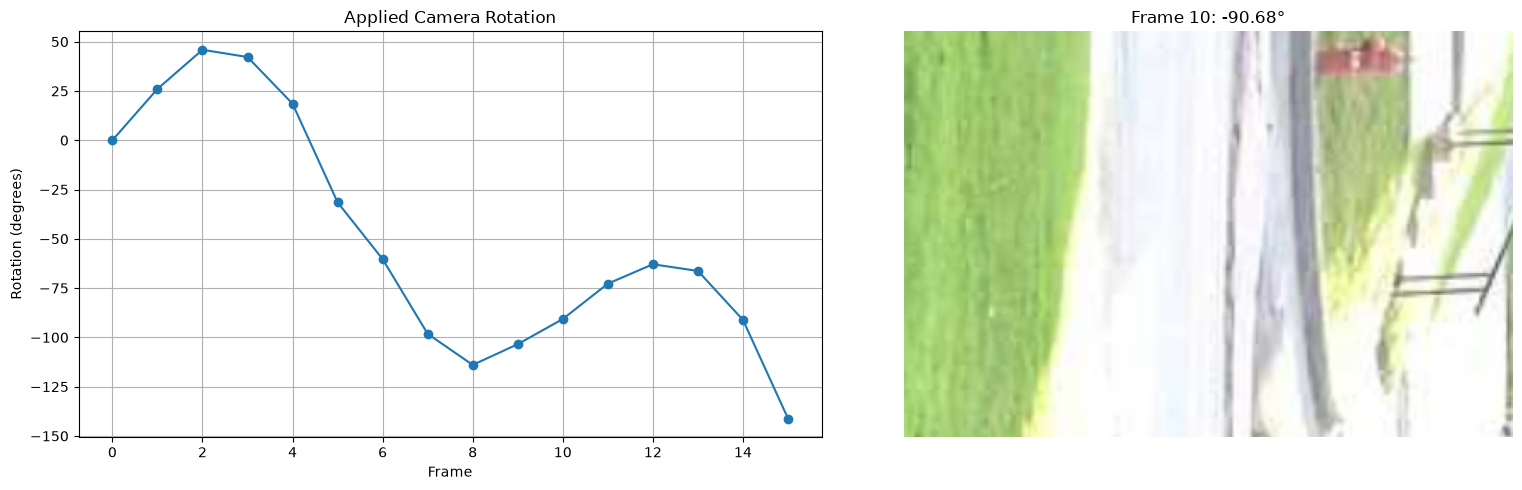

In [228]:
# Get one sample from the dataset
train_dataset.set_epoch(0)
sample = train_dataset[4]

frames = sample["rotated_frames"]
angles = sample["angles_deg"]

# Plot the rotation trajectory
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# LEFT: Rotation trajectory
axes[0].plot(
    np.arange(len(angles)),
    angles,
    marker="o"
)

axes[0].set_xlabel("Frame")
axes[0].set_ylabel("Rotation (degrees)")
axes[0].set_title("Applied Camera Rotation")
axes[0].grid(True)

# RIGHT: Example rotated frame
frame_idx = 10

axes[1].imshow(
    cv2.cvtColor(
        frames[frame_idx],
        cv2.COLOR_BGR2RGB
    )
)

axes[1].set_title(
    f"Frame {frame_idx}: {angles[frame_idx]:.2f}°"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

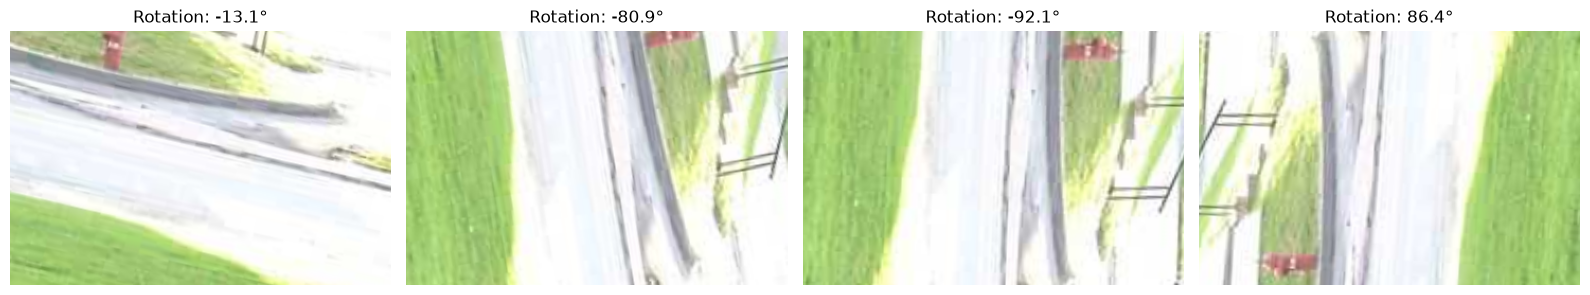

In [210]:
sample = train_dataset[0]

frames = sample["rotated_frames"]
angles = sample["angles_deg"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

indices = [1, 5, 10, 15]

for ax, i in zip(axes, indices):

    ax.imshow(
        cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB)
    )

    ax.set_title(f"Rotation: {angles[i]:.1f}°")
    ax.axis("off")

plt.tight_layout()
plt.show()